In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [2]:
ds = "EGF"

source_file = (
    Path("/home/csb/Saloni/EMT_ID/EMT_ID/Figure_time_or_dose_emt/source_data")
    / f"{ds}_ID_scores.csv"
)

data = pd.read_csv(source_file)

required_columns = {"Time", "ID"}
if not required_columns.issubset(data.columns):
    raise ValueError("The CSV must contain exactly the required data columns: Time and ID")

In [3]:
time_order = ["0d", "8h", "1d", "3d", "7d", "1d_rm", "3d_rm"]

id_groups = [
    data.loc[data["Time"] == time, "ID"].dropna().to_numpy()
    for time in time_order
]

id_means = [np.mean(group) for group in id_groups]
cell_counts = data["Time"].value_counts()

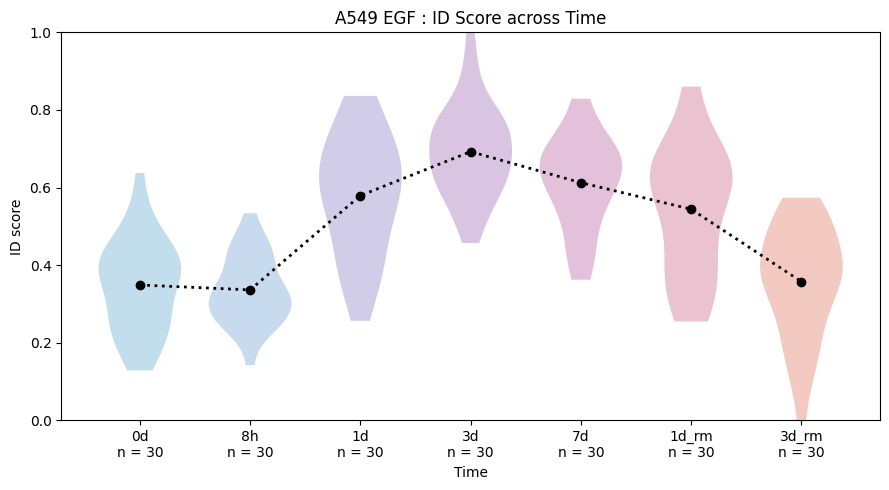

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(time_order))

pastel_colors = [
    "#B8D8E8", "#BFD4EA", "#C9C4E4", "#D3BBDD",
    "#DEB6D5", "#E8B8C8", "#F0C1B8"
]

parts = ax.violinplot(
    id_groups,
    positions=positions,
    widths=0.75,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

for body, color in zip(parts["bodies"], pastel_colors):
    body.set_facecolor(color)
    body.set_alpha(0.85)

ax.plot(
    positions,
    id_means,
    linestyle=":",
    marker="o",
    linewidth=2,
    markersize=6,
    color="black"
)

ax.set_xticks(positions)
ax.set_xticklabels([
    f"{time}\nn = {cell_counts.get(time, 0)}"
    for time in time_order
])

ax.set_xlabel("Time")
ax.set_ylabel("ID score")
ax.set_ylim(0, 1)
ax.set_title(f"A549 {ds} : ID Score across Time")

plt.tight_layout()
plt.show()

In [5]:
tukey = pairwise_tukeyhsd(
    endog=data["ID"],
    groups=data["Time"],
    alpha=0.05
)

tukey_df = pd.DataFrame(
    tukey._results_table.data[1:],
    columns=tukey._results_table.data[0]
)

tukey_df["p-adj"] = tukey_df["p-adj"].astype(float)

tukey_matrix = pd.DataFrame(
    np.nan,
    index=time_order,
    columns=time_order
)

for _, row in tukey_df.iterrows():
    tukey_matrix.loc[row["group1"], row["group2"]] = row["p-adj"]
    tukey_matrix.loc[row["group2"], row["group1"]] = row["p-adj"]

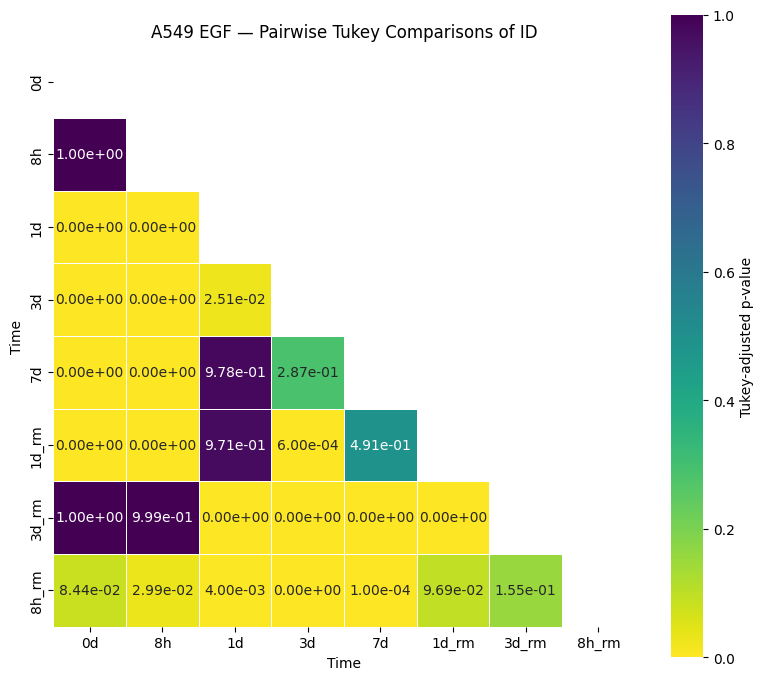

In [6]:
mask = np.triu(
    np.ones_like(tukey_matrix, dtype=bool)
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    tukey_matrix,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Tukey-adjusted p-value"}
)

plt.title(f"A549 {ds} — Pairwise Tukey Comparisons of ID")
plt.xlabel("Time")
plt.ylabel("Time")
plt.tight_layout()
plt.show()